# Figures for papers: Optical/UV diagnostic diagrams
Stephanie Juneau (NSF NOIRLab) on behalf of the AGN/Gal VAC team and GQP working group

We use this notebook to generate plots for the AGN/Galaxy Classification VAC paper. This is the DR1 version.

In [1]:
# Numpy
import numpy as np
# Plotting stuff and suppressing boring warnings
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
import warnings
warnings.filterwarnings('ignore')

# Get the GQP code
import sys
# Set the path where the py scripts are
sys.path.append("../py/")
import set_agn_masksDESI
from set_agn_masksDESI import get_agn_maskbits

# DESI targeting masks 
from desitarget import targetmask            # For Main survey
from desitarget.sv1 import sv1_targetmask    # For SV1
from desitarget.sv2 import sv2_targetmask    # For SV2
from desitarget.sv3 import sv3_targetmask    # For SV3

## SJ: Check if we're using this?!
import fitsio

# Import Astropy libraries - useful for many astronomy related function
from astropy.table import Table #, join, Column
from astropy.io import fits

# TO DO: simplify/clean this?
settings = {
    'font.size':11,
    'axes.linewidth':1.5,
    'xtick.major.size':6.0,
    'xtick.minor.size':4.0,
    'xtick.major.width':1.0,
    'xtick.minor.width':1.,
    'xtick.direction':'in', 
    'xtick.minor.visible':True,
    'xtick.top':True,
    'ytick.major.size':6.0,
    'ytick.minor.size':4.0,
    'ytick.major.width':1.0,
    'ytick.minor.width':1.,
    'ytick.direction':'in', 
    'ytick.minor.visible':True,
    'ytick.right':True,
    'axes.labelsize':11
    }

plt.rcParams.update(**settings)

## Read data

In [2]:
def return_catdir(location='nersc'):

    dl_path = '~/data/data_DESI/science/gqp/agncatalog/catalog/'
    nersc_path = '/global/cfs/cdirs/desi/science/gqp/agncatalog/dr1/v1.0/'
    if location=='datalab':
        return(dl_path)
    else:
        return(nersc_path)  #default

In [3]:
catdir = return_catdir(location='datalab')
#filename = f'{catdir}agngal_dr1_20260709.fits'
filename = f'{catdir}desi_agngal_iron_v20260903.fits' # FSF v4.0 VAC

# UPDATE this if running at NERSC or by someone else!
figdir = '/dlusers/sjuneau_user/data/data_DESI/figs/agngal_dr1/'

# Open the catalog
agn_hdul = fits.open(filename, format='fits')
agn_hdul.info()

Filename: /home/jail/./dlusers/sjuneau_user/data/data_DESI/science/gqp/agncatalog/catalog/desi_agngal_iron_v20260903.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       6   ()      
  1  AGNCAT        1 BinTableHDU    101   17995896R x 42C   [K, 7A, 6A, J, D, K, D, D, D, D, E, E, D, 6A, K, K, K, J, D, D, K, D, D, D, I, E, L, L, L, K, K, K, K, K, K, K, K, K, K, K, K, K]   
  2  AUXDATA       1 BinTableHDU    200   17995896R x 67C   [E, K, 7A, 6A, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E]   


In [4]:
%%time
# Load the catalog into Astropy tables
#T = Table(agn_hdul[1].data)
#T2 = Table(agn_hdul[2].data)
T = Table(fitsio.read(filename, ext=1))
T2 = Table(fitsio.read(filename, ext=2))

CPU times: user 23.9 s, sys: 7.31 s, total: 31.2 s
Wall time: 2min 24s


In [5]:
AGN_MASKBITS, OPT_UV_TYPE, IR_TYPE = get_agn_maskbits('../py/agnmask.yaml')

In [6]:
#T.colnames

## Define functions and color scheme

In [7]:
def add_contours(x, y, xy_range, ax=None, levels = np.power(10,np.arange(-1.6,2.4,0.4))):

    # 2-d histogram density of all the galaxies
    dens_all,_,_ = np.histogram2d(x, y, range=xy_range, bins=100, density=True)
    dens_plot = dens_all.T

    extent = (xy_range[0][0],xy_range[0][1],xy_range[1][0],xy_range[1][1])
    
    ## add overall contours
    if ax is None:
        plt.contour(dens_plot, colors='lightgrey', extent=extent, levels=levels, lw=0.5)
    else:
        ax.contour(dens_plot, colors='lightgrey', extent=extent, levels=levels, lw=0.5)

In [8]:
## Default color scheme

# Color maps
cmap_sf = 'Blues'
cmap_sy = 'Greens'
#cmap_sy = 'Reds'
#cmap_cp = 'Greys'
cmap_cp = 'Oranges'
cmap_lin = 'Purples'
cmap_ret = 'PuRd' #'YlOrBr'
cmap_pass = 'Greys' # make sure it differs from composite

# Color names for labels or lines
col_sf = 'tab:blue'
col_sy = 'seagreen'
#col_sy = 'darkred' #'crimson'
#col_cp = 'grey'
col_cp = 'orangered'
col_lin = 'rebeccapurple'
col_ret = 'purple' #'gold'
col_pass = 'grey'  # make sure it differs from composite

### BPT diagrams (3-panel figure)

In [9]:
# Demarcation lines

# [NII]
xKa03 = np.arange(-2.7,0.05,0.05)              #Kaufmann et al (2003)
yKa03 = 0.61 / (xKa03 - 0.05) + 1.3
xKe01 = np.arange(-2.7,0.47,0.05)              #Kewley et al (2001)
yKe01 = 0.61 / (xKe01 - 0.47) + 1.19
xScha07 = np.arange(-0.17, 1.3, 0.05)
yScha07 = 1.05 * xScha07 + 0.45

# [SII]
xKe06 = np.arange(-2,0.32,0.05)              #Kewley et al (2006)
yKe06 = 0.72 / (xKe06 - 0.32) + 1.30
xL21 = np.arange(-2.7,0.32,0.05)             #Law et al (2021)
yL21 = 0.648 / (xL21 - 0.324) + 1.43 # modified (+1.349 was original)
xliner_Sii = np.arange(-.23,1.5,0.05)        #Kewley et al (2006)
yliner_Sii = 1.89 * xliner_Sii + 0.76

# [OI]
xKe06_Oi = np.arange(-3,-0.59,0.05)          #Kewley et al (2006)
yKe06_Oi = 0.73 / (xKe06_Oi + 0.59) + 1.33
xL21_Oi = np.arange(-3.2,-0.124,0.05)          #Law et al (2021)
yL21_Oi = 0.884 / (xL21_Oi + 0.124) + 1.4  # modified (original was +1.291)
xliner_Oi = np.arange(-0.88,0.6,0.05) 
yliner_Oi = 1.18 * xliner_Oi + 1.3

In [10]:
# BPT variables
xx_bptnii = np.log10(T2['NII_6584_FLUX']/T2['HALPHA_FLUX'])
xx_bptsii = np.log10((T2['SII_6716_FLUX']+T2['SII_6731_FLUX'])/T2['HALPHA_FLUX'])
xx_bptoi = np.log10(T2['OI_6300_FLUX']/T2['HALPHA_FLUX'])
yy_bpt = np.log10(T2['OIII_5007_FLUX']/T2['HBETA_FLUX'])

## Define ranges
is_nii_sf = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.NII_SF != 0)
is_nii_sy = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.NII_SY != 0)
is_nii_lin = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.NII_LINER != 0)
is_nii_comp = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.NII_COMP != 0)

is_sii_sf = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.SII_SF != 0)
is_sii_sy = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.SII_SY != 0)
is_sii_lin = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.SII_LINER != 0)

is_oi_sf = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.OI_SF != 0)
is_oi_sy = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.OI_SY != 0)
is_oi_lin = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.OI_LINER != 0)

# is_available?
is_nii = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.NII_BPT != 0)
is_sii = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.SII_BPT != 0)
is_oi = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.OI_BPT != 0)

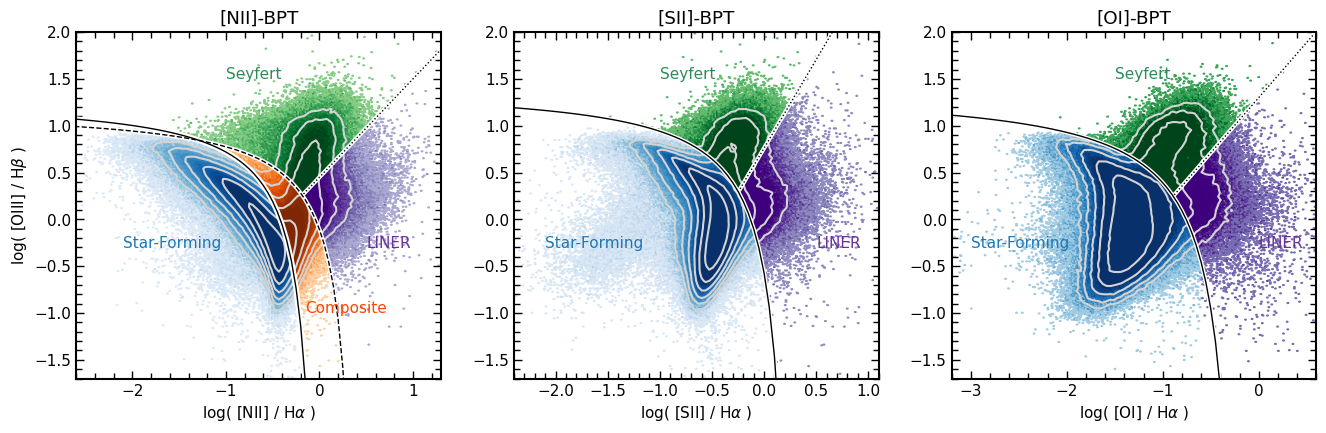

In [15]:
## BPT plots (3 panels)

## Parameters for all plots
norm_min, norm_max = 0.8, 600
norm_max_sii = 300 # use smaller value for [SII] and [OI] as there are fewer points
Nbins = 2000
gridsize = (250,250)

## Initialize figure
plt.figure(figsize = (16,4.5))

## BPT-[NII]
plt.subplot2grid((1,3), (0,0))
xlim = [-2.6,1.3]
ylim = [-1.7,2.]
extent = [xlim[0],xlim[1],ylim[0], ylim[1]]
plt.title('[NII]-BPT')
plt.hexbin(xx_bptnii[is_nii_sf], yy_bpt[is_nii_sf], bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max), cmap=cmap_sf, extent=extent)
plt.hexbin(xx_bptnii[is_nii_comp], yy_bpt[is_nii_comp], bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max), cmap=cmap_cp, extent=extent)
plt.hexbin(xx_bptnii[is_nii_sy], yy_bpt[is_nii_sy], bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max), cmap=cmap_sy, extent=extent)
plt.hexbin(xx_bptnii[is_nii_lin], yy_bpt[is_nii_lin], bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max), cmap=cmap_lin, extent=extent)
plt.xlabel('log( [NII] / H$\\alpha$ )')
plt.ylabel('log( [OIII] / H$\\beta$ )')
plt.xlim(xlim)
plt.ylim(ylim)

# Contours
add_contours(xx_bptnii[is_nii], yy_bpt[is_nii], [xlim, ylim])

# Lines
plt.plot(xKa03,yKa03,color='w',alpha=1,lw=4)
plt.plot(xKe01,yKe01,color='w',alpha=1,lw=3)
plt.plot(xScha07,yScha07,color='w',alpha=1,lw=3)
plt.plot(xKa03,yKa03,color='k',alpha=1,lw=1)
plt.plot(xKe01,yKe01,color='k',alpha=1,lw=1,ls='--')
plt.plot(xScha07,yScha07,color='k',alpha=1,lw=1,ls=':')

# Labels
plt.text(-1, 1.5, "Seyfert", color=col_sy)
plt.text(0.5, -0.3, "LINER", color=col_lin)
plt.text(-2.1, -0.3, "Star-Forming", color=col_sf)
plt.text(-0.15, -1.0, "Composite", color=col_cp)

## BPT-[SII]
plt.subplot2grid((1,3), (0,1))
xlim = [-2.4,1.1]
extent = [xlim[0],xlim[1],ylim[0], ylim[1]]

plt.title('[SII]-BPT')
plt.hexbin(xx_bptsii[is_sii_sf], yy_bpt[is_sii_sf], bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max_sii), cmap=cmap_sf, extent=extent)
plt.hexbin(xx_bptsii[is_sii_sy], yy_bpt[is_sii_sy], bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max_sii), cmap=cmap_sy, extent=extent)
plt.hexbin(xx_bptsii[is_sii_lin], yy_bpt[is_sii_lin], bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max_sii), cmap=cmap_lin, extent=extent)
plt.xlabel('log( [SII] / H$\\alpha$ )')
#plt.ylabel('log( [OIII] / H$\\beta$ )')
plt.xlim(xlim)
plt.ylim(ylim)

# Contours
add_contours(xx_bptsii[is_sii], yy_bpt[is_sii], [xlim, ylim])

# Lines
plt.plot(xL21,yL21,color='w',alpha=1,lw=3)
plt.plot(xliner_Sii,yliner_Sii,color='w',alpha=1,lw=3)
plt.plot(xL21,yL21,color='k',alpha=1,lw=1)
plt.plot(xliner_Sii,yliner_Sii,color='k',alpha=1,lw=1,ls=':')

# Labels
plt.text(-1, 1.5, "Seyfert", color=col_sy)
plt.text(0.5, -0.3, "LINER", color=col_lin)
plt.text(-2.1, -0.3, "Star-Forming", color=col_sf)

## BPT-[OI]
plt.subplot2grid((1,3), (0,2))
xlim = [-3.2,0.6]
extent = [xlim[0],xlim[1],ylim[0], ylim[1]]

plt.title('[OI]-BPT')
plt.hexbin(xx_bptoi[is_oi_sf], yy_bpt[is_oi_sf], bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max_sii), cmap=cmap_sf, extent=extent)
plt.hexbin(xx_bptoi[is_oi_sy], yy_bpt[is_oi_sy], bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max_sii), cmap=cmap_sy, extent=extent)
plt.hexbin(xx_bptoi[is_oi_lin], yy_bpt[is_oi_lin], bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max_sii), cmap=cmap_lin, extent=extent)
plt.xlabel('log( [OI] / H$\\alpha$ )')
#plt.ylabel('log( [OIII] / H$\\beta$ )')
plt.xlim(xlim)
plt.ylim(ylim)

# Contours
add_contours(xx_bptoi[is_oi], yy_bpt[is_oi], [xlim, ylim])

# Lines
plt.plot(xL21_Oi,yL21_Oi,color='w',alpha=1,lw=3)
plt.plot(xliner_Oi,yliner_Oi,color='w',alpha=1,lw=3)
plt.plot(xL21_Oi,yL21_Oi,color='k',alpha=1,lw=1)
plt.plot(xliner_Oi,yliner_Oi,color='k',alpha=1,lw=1,ls=':')

# Labels
plt.text(-1.5, 1.5, "Seyfert", color=col_sy)
plt.text(0.0, -0.3, "LINER", color=col_lin)
plt.text(-3., -0.3, "Star-Forming", color=col_sf)

plt.savefig(f'{figdir}agngal_vac_BPT_DR1.png',format='png',bbox_inches='tight',dpi=150)
plt.show()

### WHAN

In [16]:
#we define the masks required for the classification of AGNs for the WHAN BPT diagram
is_whan_av = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.WHAN !=0)

#creating the subcatalog for the objects for which the WHAN is available
xx_Wha = np.log10((T2['NII_6584_FLUX']/T2['HALPHA_FLUX'])) 
yy_Wha = np.log10(T2['HALPHA_EW']) #getting the width of H-alpha line

#creating the masks for different WHAN objects
is_whan_sf = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.WHAN_SF !=0)  #Star forming galaxies mask
is_whan_sagn = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.WHAN_SAGN != 0) #strong AGN mask
is_whan_wagn = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.WHAN_WAGN != 0) #weak AGN mask
is_whan_ret = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.WHAN_RET !=0) #retired galaxies mask
is_whan_pass = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.WHAN_PASS !=0) #passive galaxies mask

#for passive galaxies, filter required to remove negative values encountered
x_passive = xx_Wha[is_whan_pass] 
y_passive = yy_Wha[is_whan_pass]
#passive_mask = y_passive>0.
#x_passive = x_passive[passive_mask]
#y_passive = y_passive[passive_mask]

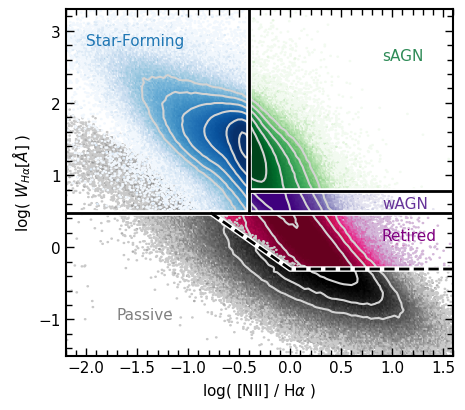

In [17]:
#initializing the figure properties
plt.figure(figsize=(5,4.5))
#plt.title('WHAN diagram')
xlim = [-2.2, 1.6]
ylim = [-1.5, 3.3] #np.log10([0.1, 2e3])
extent = [xlim[0],xlim[1],ylim[0], ylim[1]]

norm_min, norm_max = 0.8, 1000
Nbins = 2000
gridsize = (300,200)

#creating the WHAN diagram
plt.hexbin(xx_Wha[is_whan_wagn], yy_Wha[is_whan_wagn], cmap=cmap_lin, bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max), extent=extent)
plt.hexbin(xx_Wha[is_whan_sagn], yy_Wha[is_whan_sagn], cmap=cmap_sy, bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max), extent=extent)
plt.hexbin(xx_Wha[is_whan_ret], yy_Wha[is_whan_ret], cmap=cmap_ret, bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max), extent=extent)
plt.hexbin(x_passive, y_passive, cmap=cmap_pass, bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max), extent=extent)
plt.hexbin(xx_Wha[is_whan_sf], yy_Wha[is_whan_sf], cmap=cmap_sf, bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max), extent=extent)

# Contours
add_contours(xx_Wha[is_whan_av], yy_Wha[is_whan_av], [xlim, ylim])

#defining the theoretical cuts for different objects
x_cutoff_SF = -0.4 
y_cutoff_sAGN = np.log10(6.) #strong AGN WHAN cutoff criteria
#star forming WHAN cutoff criteria
x_ret_vs_passive = [np.log10(0.5/3.), 0, xlim[1]]
y_ret_vs_passive = [np.log10(3.), np.log10(0.5), np.log10(0.5)]

# White lines in background
plt.plot([x_cutoff_SF, x_cutoff_SF], np.log10([3, 2e3]), color='w', lw=4)
plt.plot([-0.4, xlim[1]], [y_cutoff_sAGN, y_cutoff_sAGN], color='w', lw=4)
plt.axhline(y=np.log10(3.), color='w', lw=4) #criteria for the retired galaxies, also referred to as the fake AGNs
plt.plot(x_ret_vs_passive, y_ret_vs_passive, color='w', lw=4)

# Black lines
plt.plot([x_cutoff_SF, x_cutoff_SF], np.log10([3, 2e3]), color='black', lw=2)
plt.plot([-0.4, xlim[1]], [y_cutoff_sAGN, y_cutoff_sAGN], color='black', lw=2)
plt.axhline(y=np.log10(3.), color='black', lw=2) #criteria for the retired galaxies, also referred to as the fake AGNs
plt.plot(x_ret_vs_passive, y_ret_vs_passive, color='k', lw=2, ls='--')

plt.xlabel('log( [NII] / H$\\alpha$ )') 
plt.ylabel('log( $W_{H\\alpha} [{\AA}]$ )')
#defining the limits of the plot
plt.xlim(xlim)
plt.ylim(ylim)

## Labels
plt.text(-2.,2.8,'Star-Forming',fontsize=11,color=col_sf) #,backgroundcolor='white')
plt.text(0.9,2.6,'sAGN',fontsize=11,color=col_sy)
plt.text(0.9,0.55,'wAGN',fontsize=11,color=col_lin)
plt.text(0.9,0.1,'Retired',fontsize=11,color=col_ret)
plt.text(-1.7,-1.,'Passive',fontsize=11,color=col_pass)

plt.savefig(f'{figdir}agngal_vac_WHAN_DR1.png',format='png',bbox_inches='tight',dpi=150)
plt.show()


### Blue

#### ** Changing to EW ratio for Oiii/Hb

In [45]:
snr_oiii = T2['OIII_5007_FLUX'] * np.sqrt(T2['OIII_5007_FLUX_IVAR'])
snr_hb = T2['HBETA_FLUX'] * np.sqrt(T2['HBETA_FLUX_IVAR'])
#snr_oii_1 = T2['OII_3726_EW'] * np.sqrt(T2['OII_3726_EW_IVAR'])
snr_oii_1 = T2['OII_3726_FLUX'] * np.sqrt(T2['OII_3726_FLUX_IVAR'])
snr_oii_2 = T2['OII_3729_FLUX'] * np.sqrt(T2['OII_3729_FLUX_IVAR'])

In [46]:
# Set our plotting data axes 
xx_blue = np.log10((T2['OII_3726_EW']+T2['OII_3729_EW']) / T2['HBETA_EW'])
#yy_blue = np.log10(T2['OIII_5007_FLUX'] / T2['HBETA_FLUX'])
yy_blue = np.log10(T2['OIII_5007_EW'] / T2['HBETA_EW'])

In [47]:
# lines
xx_blue_main_lines = np.linspace(-2., 0.9, num=200)
xx_blue_slc_lines = np.linspace(0.09, 1.06)
blue_main_line = 0.11 / (xx_blue_main_lines - 0.92) + 0.85
blue_eq3a = -(xx_blue_slc_lines - 1.)**2 - 0.1 * xx_blue_slc_lines + 0.25
blue_eq3b = (xx_blue_slc_lines - 0.2)**2 - 0.6


In [51]:
# Create masks for each of the Blue diagnostic subsets
blue_av_mask = T['OPT_UV_TYPE'] & OPT_UV_TYPE.BLUE != 0 
blue_agn_mask = T['OPT_UV_TYPE'] & OPT_UV_TYPE.BLUE_AGN != 0
blue_slc_mask = T['OPT_UV_TYPE'] & OPT_UV_TYPE.BLUE_SLC != 0
blue_liner_mask = T['OPT_UV_TYPE'] & OPT_UV_TYPE.BLUE_LINER != 0
blue_sf_mask = T['OPT_UV_TYPE'] & OPT_UV_TYPE.BLUE_SF != 0
blue_sfagn_mask = T['OPT_UV_TYPE'] & OPT_UV_TYPE.BLUE_SFAGN != 0

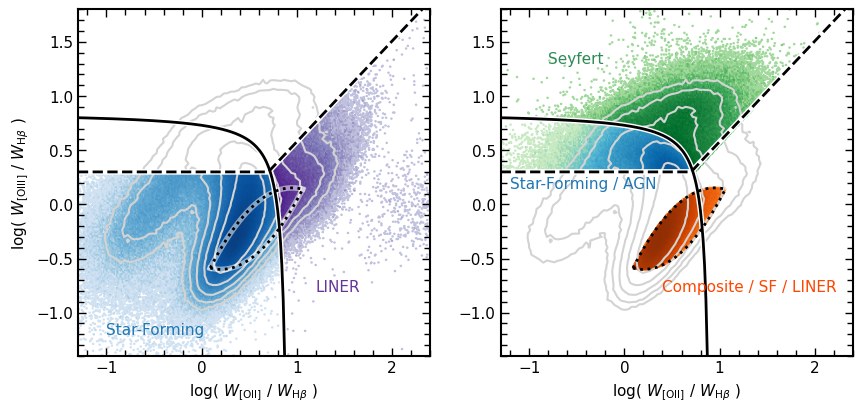

In [61]:
fig, (ax, bx) = plt.subplots(ncols=2, figsize=(10, 4.5))
xlim = [-1.3, 2.4]
ylim = [-1.4, 1.8]
extent = [xlim[0],xlim[1],ylim[0], ylim[1]]

norm_min, norm_max = 0.8, 3000
Nbins = 2000
gridsize = (300,200)

# For testing purposes
rsel = blue_av_mask  #keeps everything
#rsel = snr_hb >= 20.
#rsel = (snr_oii_1 >= 20.)&(snr_oii_2 >= 20.)

ax.hexbin(xx_blue[blue_sf_mask&rsel], yy_blue[blue_sf_mask&rsel], cmap=cmap_sf, 
          bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max), extent=extent)
ax.hexbin(xx_blue[blue_liner_mask&rsel], yy_blue[blue_liner_mask&rsel], cmap=cmap_lin, 
          bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max), extent=extent)

# Contours
add_contours(xx_blue[blue_av_mask], yy_blue[blue_av_mask], [xlim, ylim], ax=ax)


xx_blue_sfagnlin = [xlim[0], 0.7, xlim[1]]
yy_blue_sfagnlin = [0.3, 0.3, 0.95*xlim[1]-0.4]

# Demarcations
ax.plot(xx_blue_main_lines, blue_main_line, color='w', lw=4)
ax.plot(xx_blue_slc_lines, blue_eq3a, color='w', lw=4, alpha=0.5)
ax.plot(xx_blue_slc_lines, blue_eq3b, color='w', lw=4, alpha=0.5)
ax.plot(xx_blue_sfagnlin, yy_blue_sfagnlin, color='w', lw=4)

# black lines
ax.plot(xx_blue_main_lines, blue_main_line, color='k', lw=2)
ax.plot(xx_blue_slc_lines, blue_eq3a, color='k', ls=':', lw=2)
ax.plot(xx_blue_slc_lines, blue_eq3b, color='k', ls=':', lw=2)
ax.plot(xx_blue_sfagnlin, yy_blue_sfagnlin, color='k', ls='--', lw=2)

# Set axis labels and ranges
ax.set(xlabel=r'log( $W_{[\mathrm{OII}]}~/~W_{\mathrm{H}\beta}$ )',
       ylabel=r'log( $W_{[\mathrm{OIII}]}~/~W_{\mathrm{H}\beta}$ )',
       xlim=xlim, ylim=ylim)
#\lambda 5007
# r'$\log( EW([\mathrm{OII}]\lambda3726,\lambda 3729) / EW(\mathrm{H}\beta))$'

# Labels
ax.text(1.2, -0.8, "LINER", color=col_lin)
ax.text(-1, -1.2, "Star-Forming", color=col_sf)


# 2nd panel
bx.hexbin(xx_blue[blue_slc_mask], yy_blue[blue_slc_mask], cmap=cmap_cp, 
          bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max), extent=extent)
bx.hexbin(xx_blue[blue_agn_mask], yy_blue[blue_agn_mask], cmap=cmap_sy, 
          bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max), extent=extent)
bx.hexbin(xx_blue[blue_sfagn_mask], yy_blue[blue_sfagn_mask], cmap='GnBu', 
          bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max), extent=extent)

# Contours
add_contours(xx_blue[blue_av_mask], yy_blue[blue_av_mask], [xlim, ylim], ax=bx)

# Demarcations
bx.plot(xx_blue_main_lines, blue_main_line, color='w', lw=4)
#bx.plot(xx_blue_slc_lines, blue_eq3a, color='w', lw=4)
#bx.plot(xx_blue_slc_lines, blue_eq3b, color='w', lw=4)
bx.plot(xx_blue_sfagnlin, yy_blue_sfagnlin, color='w', lw=4)

# black lines
bx.plot(xx_blue_main_lines, blue_main_line, color='k', lw=2)
bx.plot(xx_blue_slc_lines, blue_eq3a, color='k', ls=':', lw=2)
bx.plot(xx_blue_slc_lines, blue_eq3b, color='k', ls=':', lw=2)
bx.plot(xx_blue_sfagnlin, yy_blue_sfagnlin, color='k', ls='--', lw=2)

# Set axis labels and ranges
bx.set(xlabel=r'log( $W_{[\mathrm{OII}]}~/~W_{\mathrm{H}\beta}$ )', 
       xlim=xlim, ylim=ylim)

# Labels
bx.text(-0.8, 1.3, "Seyfert", color=col_sy)
bx.text(-1.2, 0.15, "Star-Forming / AGN", color=col_sf)
bx.text(0.4, -0.8, "Composite / SF / LINER", color=col_cp)

plt.savefig(f'{figdir}agngal_vac_Blue_DR1.png',format='png',bbox_inches='tight',dpi=150)
plt.show()

### MEx

In [22]:
# Stellar mass from T2
log_mass = T2['LOGMSTAR']

# [OIII]/Hbeta flux ratio
oiii_hbeta = np.log10(T2['OIII_5007_FLUX'] / T2['HBETA_FLUX'])

# Masks
is_mex_av = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.MEX != 0)
is_mex_sf = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.MEX_SF != 0)
is_mex_intermediate = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.MEX_INTERM != 0)
is_mex_agn = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.MEX_AGN != 0)

In [23]:
# Define the 2014 MEx demarcation lines (Juneau+2014)
def mex_upper_2014(x):
    """AGN vs Composite boundary from Juneau 2014 (Equation 1)"""
    a0, a1, a2, a3 = 410.24, -109.333, 9.71731, -0.288244
    return np.where(x <= 10, 0.375/(x - 10.5) + 1.14, a0 + a1*x + a2*x**2 + a3*x**3)

def mex_lower_2014(x):
    """Composite vs Star-forming boundary from Juneau 2014 (Equation 2)"""
    a0, a1, a2, a3 = 352.066, -93.8249, 8.32651, -0.246416
    return np.where(x <= 9.6, 0.375/(x - 10.5) + 1.14, a0 + a1*x + a2*x**2 + a3*x**3)

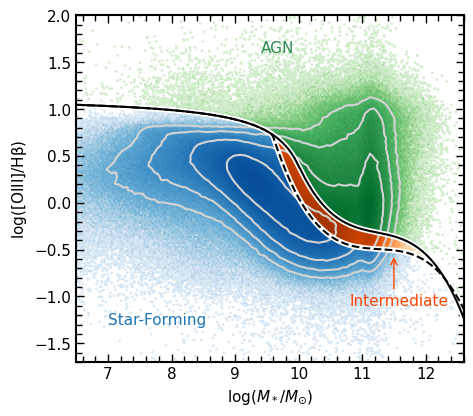

In [24]:
mass_range = np.linspace(6.5, 13, 200)

plt.figure(figsize=(5, 4.5))
xlim = [6.5, 12.6]
ylim = [-1.7, 2.0]
extent = [xlim[0],xlim[1],ylim[0], ylim[1]]

# Adjust gridsize to make hexagons smaller/bigger
gridsize = 300  
norm_min, norm_max = 0.8, 5e3
Nbins = 2000

# Hexbin plots for each classification
hb_sf = plt.hexbin(log_mass[is_mex_sf], oiii_hbeta[is_mex_sf],cmap=cmap_sf, 
          bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max), extent=extent)
hb_composite = plt.hexbin(log_mass[is_mex_intermediate], oiii_hbeta[is_mex_intermediate], cmap=cmap_cp, 
          bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max), extent=extent)
hb_agn = plt.hexbin(log_mass[is_mex_agn], oiii_hbeta[is_mex_agn], cmap=cmap_sy, 
          bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max), extent=extent)

# Contours
add_contours(log_mass[is_mex_av], oiii_hbeta[is_mex_av], [xlim, ylim])

# Plot the MEx classification lines
plt.plot(mass_range, mex_upper_2014(mass_range), 'w', linewidth=4)  
plt.plot(mass_range, mex_lower_2014(mass_range), 'w', linewidth=4)  

# Plot the MEx classification lines
plt.plot(mass_range, mex_upper_2014(mass_range), 'black', linewidth=1.5, label="AGN/SF boundary")  
plt.plot(mass_range, mex_lower_2014(mass_range), 'black', linewidth=1.5, ls='--', label="Intermediate/SF boundary")  

# Labels
plt.text(7,-1.3,'Star-Forming',fontsize=11,color=col_sf) #,backgroundcolor='white')
plt.text(9.4,1.6,'AGN',fontsize=11,color=col_sy)
plt.text(10.8,-1.1,'Intermediate',fontsize=11,color=col_cp)  #, rotation=-30)

# Add the arrow
plt.annotate(
    "",                      # Empty string so no text is displayed
    xy=(11.5, -0.55),               # Coordinates for the arrow HEAD
    xytext=(11.5, -0.95),           # Coordinates for the arrow TAIL
    arrowprops=dict(
        arrowstyle="->",     # Style of the arrow head
        color=col_cp,         # Line color
        lw=1                 # Line width
    )
)

plt.xlabel(r'$\log (M_*/M_{\odot})$')
plt.ylabel(r'$\log (\mathrm{[OIII]}/\mathrm{H\beta})$')
plt.xlim(xlim)
plt.ylim(ylim)
#plt.title("Mass-Excitation (MEx) Diagram (Juneau 2014)", fontsize=14)

plt.savefig(f'{figdir}agngal_vac_MEx_DR1.png',format='png',bbox_inches='tight',dpi=150)
plt.show()

## KEx

In [25]:
# Define KEx classification boundaries (Zhang & Hao 2018)
def kex_upper(sigma_log):
    """AGN vs. SF boundary from Zhang & Hao 2018 (Equation 1)"""
    return -2 * sigma_log + 4.2

def kex_lower(sigma_log):
    """SF vs. Composite boundary from Zhang & Hao 2018 (Equation 2)"""
    return np.full_like(sigma_log, 0.3)  # Constant line at y = 0.3

In [26]:
# Extract velocity dispersion (log scale) from [OIII] sigma
log_sigma_oiii = np.log10(T2['OIII_5007_SIGMA'])  

# Compute log([OIII]/Hβ)
oiii_hbeta = np.log10(T2['OIII_5007_FLUX'] / T2['HBETA_FLUX'])  

# Masks
is_kex_av = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.KEX != 0)
is_kex_sf = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.KEX_SF != 0)
is_kex_intermediate = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.KEX_INTERM != 0)
is_kex_agn = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.KEX_AGN != 0)

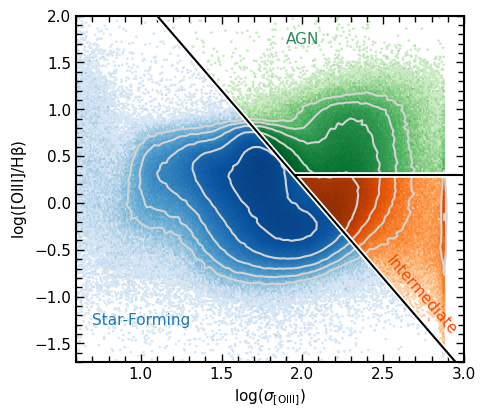

In [27]:
sigma_range = np.linspace(0, 3, 200)

plt.figure(figsize=(5, 4.5))

xlim = [0.6, 3]
ylim = [-1.7, 2.0]
extent = [xlim[0],xlim[1],ylim[0], ylim[1]]

# Adjust gridsize to make hexagons smaller/bigger
gridsize = 300  
norm_min, norm_max = 0.8, 3e3
Nbins = 2000

# Hexbin plots for each classification
hb_sf = plt.hexbin(log_sigma_oiii[is_kex_sf], oiii_hbeta[is_kex_sf],cmap=cmap_sf, 
          bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max), extent=extent)
hb_composite = plt.hexbin(log_sigma_oiii[is_kex_intermediate], oiii_hbeta[is_kex_intermediate],  cmap=cmap_cp, 
          bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max), extent=extent)
hb_agn = plt.hexbin(log_sigma_oiii[is_kex_agn], oiii_hbeta[is_kex_agn], cmap=cmap_sy, 
          bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max), extent=extent) 

# Contours
add_contours(log_sigma_oiii[is_kex_av], oiii_hbeta[is_kex_av], [xlim, ylim])

# Overlay classification curves
# Overlay AGN/SF boundary
plt.plot(sigma_range, kex_upper(sigma_range), 'w', linewidth=4)

# Overlay Composite/SF boundary **only where AGN exists**
sigma_range_composite = sigma_range[sigma_range > 1.95]
plt.plot(sigma_range_composite, kex_lower(sigma_range_composite), 'w', linewidth=4)

# Black lines
plt.plot(sigma_range, kex_upper(sigma_range), 'black', linewidth=1.5, label="AGN/SF boundary")
plt.plot(sigma_range_composite, kex_lower(sigma_range_composite), 'black', linewidth=1.5, label="Intermediate/SF boundary")

# Labels
plt.text(0.7,-1.3,'Star-Forming',fontsize=11,color=col_sf) #,backgroundcolor='white')
plt.text(1.9,1.7,'AGN',fontsize=11,color=col_sy)
plt.text(2.5,-1.4,'Intermediate',fontsize=11,color=col_cp, rotation=-49)

plt.xlabel(r'$\log(\sigma_{\mathrm{[OIII]}})$')
plt.ylabel(r'$\log (\mathrm{[OIII]}/\mathrm{H\beta})$')
#plt.title("Kinematics-Excitation (KEx) Diagram (Zhang & Hao 2018)", fontsize=13)
plt.ylim(ylim)
plt.xlim(xlim)

plt.savefig(f'{figdir}agngal_vac_KEx_DR1.png',format='png',bbox_inches='tight',dpi=150)
plt.show()

## He II

In [68]:
heii_flux = np.log10(T2['HEII_4686_FLUX'])
heii_snr = np.log10(T2['HEII_4686_FLUX'] * np.sqrt(T2['HEII_4686_FLUX_IVAR']))

In [69]:
# Axes
xx_bptnii = np.log10(T2['NII_6584_FLUX']/T2['HALPHA_FLUX'])
yy_bptheii = np.log10(T2['HEII_4686_FLUX']/T2['HBETA_FLUX'])

# Masks
is_heii_av = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.HEII_BPT != 0)      # available
is_heii_sf = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.HEII_SF != 0)
is_heii_agn = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.HEII_AGN != 0)

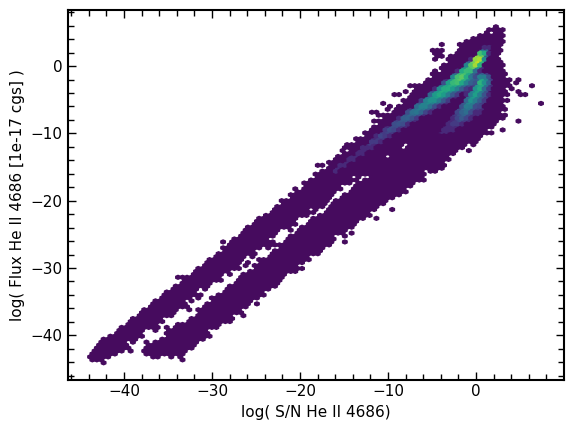

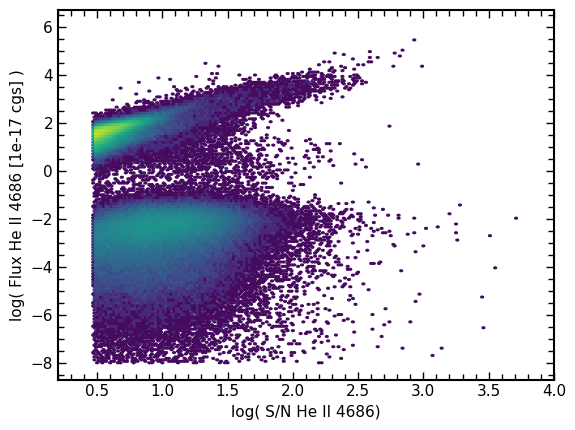

In [81]:
plt.hexbin(heii_snr, heii_flux, gridsize=100, bins=1000, norm=LogNorm(0.8, 2e3))
plt.xlabel('log( S/N He II 4686)')
plt.ylabel('log( Flux He II 4686 [1e-17 cgs] )')
plt.show()

extent = [0,4,-8,6]
plt.hexbin(heii_snr[is_heii_av], heii_flux[is_heii_av], gridsize=200, bins=1000, norm=LogNorm(0.8, 2e3), extent=extent)
plt.xlabel('log( S/N He II 4686)')
plt.ylabel('log( Flux He II 4686 [1e-17 cgs] )')
plt.xlim(0.2,4)
plt.show()

In [75]:
# log10(flux_heii_4685/flux_hbeta)=-1.22+1/(8.92*log10(flux_nii_6583/flux_halpha)+1.32)
x_heiiline = np.linspace(-3,-1.32/8.92,70)
y_heiiline = -1.22+1/(8.92*x_heiiline+1.32)

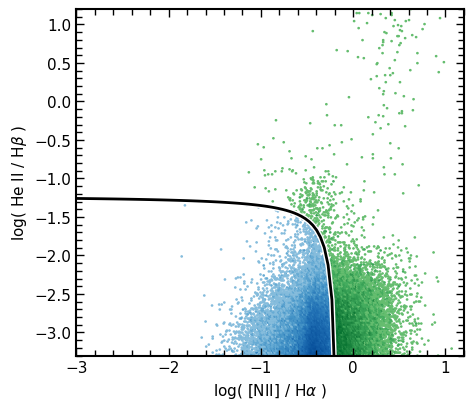

In [78]:
plt.figure(figsize=(5, 4.5))
xlim = [-3., 1.2]
ylim = [-3.3, 1.2]
extent = [xlim[0],xlim[1],ylim[0], ylim[1]]

gridsize = 300  
norm_min, norm_max = 0.8, 5e3
Nbins = 2000

rsel = heii_flux < 0.

#plt.title('He II')
plt.hexbin(xx_bptnii[is_heii_sf&rsel], yy_bptheii[is_heii_sf&rsel],cmap=cmap_sf, 
          bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max), extent=extent)
plt.hexbin(xx_bptnii[is_heii_agn&rsel], yy_bptheii[is_heii_agn&rsel],cmap=cmap_sy, 
          bins=Nbins, gridsize=gridsize, norm=LogNorm(norm_min, norm_max), extent=extent)

# Contours
#add_contours(xx_bptnii[is_heii_av], yy_bptheii[is_heii_av], [xlim, ylim])

# Line
plt.plot(x_heiiline, y_heiiline, color='w', lw=4)
plt.plot(x_heiiline, y_heiiline, color='k', lw=2)

plt.xlabel('log( [NII] / H$\\alpha$ )')
plt.ylabel('log( He II / H$\\beta$ )')
plt.xlim(xlim)
plt.ylim(ylim)

plt.savefig(f'{figdir}agngal_vac_HeII_DR1.png',format='png',bbox_inches='tight',dpi=150)
plt.show()

## [NeV]

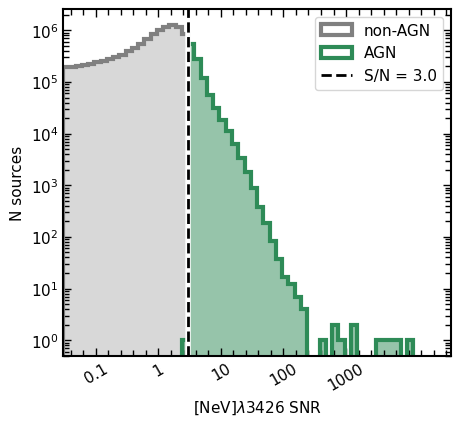

In [34]:
# Color names for labels or lines
col_other = 'grey'

# availability flags
nev_avail = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.NEV != 0)
nev_agn = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.NEV_AGN != 0)
nev_nonagn = (T['OPT_UV_TYPE'] & OPT_UV_TYPE.NEV_SF != 0)

# SNR threshold
snr_thold = 3.
log_snr_thold = np.log10(snr_thold)
snr_nev = np.float64(T2['NEV_3426_FLUX']*np.sqrt(T2['NEV_3426_FLUX_IVAR']))
log_snr_nev = np.log10(snr_nev)

# plot
fig, ax1 = plt.subplots(1, 1, figsize=(5,4.5))

#bins = np.arange(log_snr_thold-2,log_snr_thold+3,0.5)
bins = np.arange(log_snr_thold-2,log_snr_thold+4,0.1)

ax1.hist(log_snr_nev[nev_nonagn], color = col_other, label='non-AGN', bins=bins, histtype='step', linewidth=3., log=True)
ax1.hist(log_snr_nev[nev_nonagn], color = col_other, bins=bins, histtype='stepfilled', alpha=0.3, log=True)
ax1.hist(log_snr_nev[nev_agn], color = col_sy, label='AGN', bins=bins, histtype='step', linewidth=3., log=True)
ax1.hist(log_snr_nev[nev_agn], color = col_sy, bins=bins, histtype='stepfilled', alpha=0.5, log=True)

# Line for threshold
ax1.axvline(log_snr_thold, lw=4, color='w')
ax1.axvline(log_snr_thold, ls='--', lw=2, color='k', label=f'S/N = {snr_thold}')

ax1.set_xlabel('[NeV]$\lambda$3426 SNR')
ax1.set_ylabel('N sources')

xlim = ax1.get_xlim()
ax1.set_xlim(np.log10(snr_thold)-2, xlim[1])
ax1.set_xticks([-1,0,1,2,3], labels=[f'{10**val:n}' for val in [-1,0,1,2,3]], rotation=30)

ax1.legend()
plt.savefig(f'{figdir}agngal_VAC_NeV_DR1.jpg', dpi=144, bbox_inches='tight')
plt.show()